# Diamond Price Prediction — Model Training

Trains a regression model on the [Kaggle Diamonds dataset](https://www.kaggle.com/datasets/shivam2503/diamonds) using all 9 input columns
(`carat, cut, color, clarity, depth, table, x, y, z`) to predict `price` (USD).

**Steps**
1. Load & inspect data
2. Clean (remove impossible / typo dimensions)
3. Exploratory analysis
4. Build a preprocessing + model pipeline
5. Compare Linear Regression, Random Forest and XGBoost (5-fold CV)
6. Evaluate the best model on a held-out test set
7. Save the full pipeline + metadata for the Streamlit app (`models/`)

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from xgboost import XGBRegressor

RANDOM_STATE = 42
DATA_PATH = Path("data/diamonds.csv")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1


## 1. Load & inspect

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])  # drop CSV index column
print(df.shape)
df.head()

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.7 MB

Missing values: 0
Duplicate rows: 146


,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


## 2. Cleaning

- `x`, `y`, `z` (length / width / depth in mm) of **0** are physically impossible → drop.
- A few rows have extreme values (e.g. `y = 58.9 mm`, `z = 31.8 mm`) that are clearly data-entry errors → drop anything above 15 mm.
- Exact duplicate rows are dropped so the same diamond can't land in both train and test.

In [4]:
before = len(df)
df = df.drop_duplicates()
dims_ok = (df[["x", "y", "z"]] > 0).all(axis=1) & (df[["x", "y", "z"]] <= 15).all(axis=1)
df = df[dims_ok].reset_index(drop=True)
print(f"Removed {before - len(df)} rows -> {len(df)} remaining")

Removed 168 rows -> 53772 remaining


## 3. Exploratory analysis

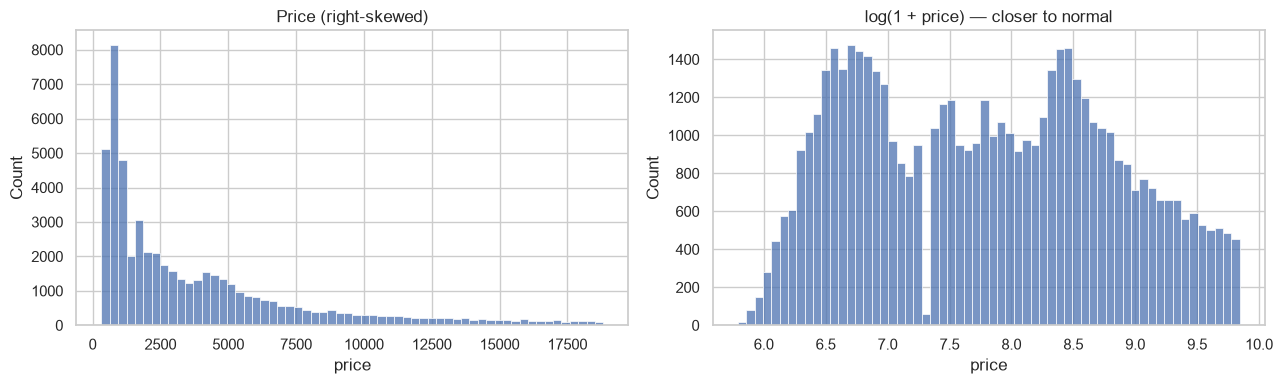

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], bins=60, ax=axes[0]).set_title("Price (right-skewed)")
sns.histplot(np.log1p(df["price"]), bins=60, ax=axes[1]).set_title("log(1 + price) — closer to normal")
plt.tight_layout(); plt.show()

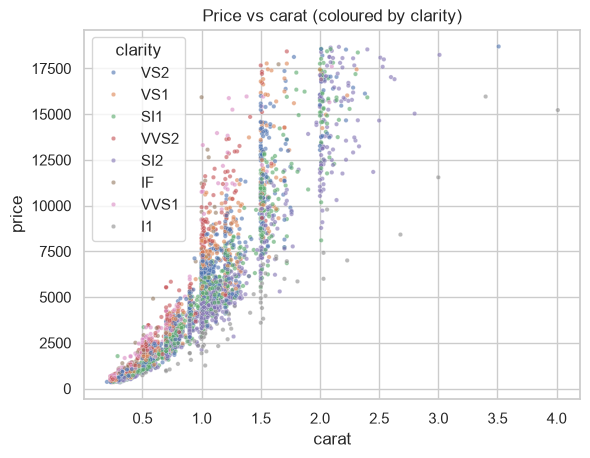

In [6]:
sns.scatterplot(data=df.sample(5000, random_state=RANDOM_STATE), x="carat", y="price", hue="clarity", s=10, alpha=.6)
plt.title("Price vs carat (coloured by clarity)"); plt.show()

Grades have a natural order, so they are encoded as ordered integers (worst → best):

| Column | Order (worst → best) |
|---|---|
| cut | Fair, Good, Very Good, Premium, Ideal |
| color | J, I, H, G, F, E, D |
| clarity | I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF |

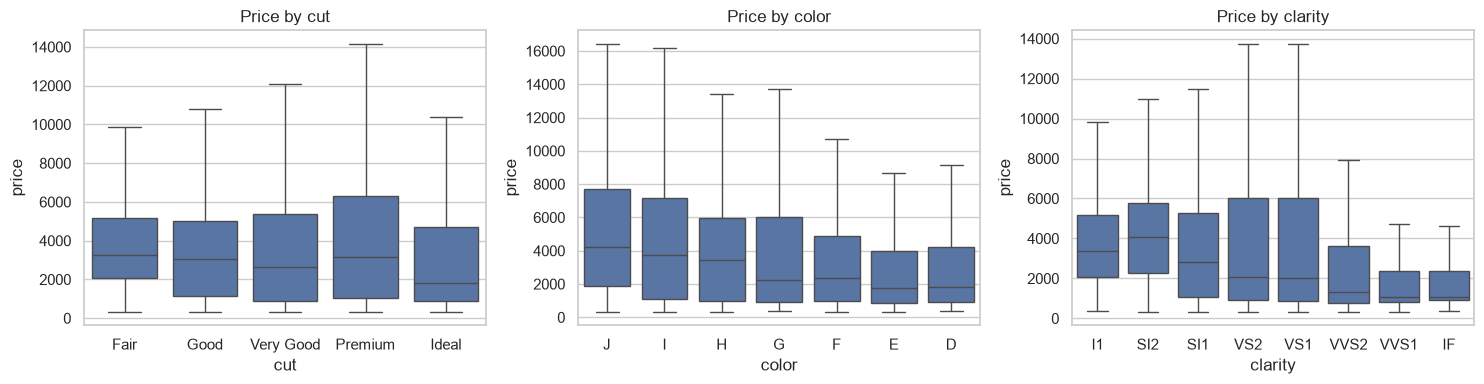

In [7]:
CATEGORY_ORDER = {
    "cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"],
    "color": ["J", "I", "H", "G", "F", "E", "D"],
    "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"],
}
CAT_COLS = list(CATEGORY_ORDER)
NUM_COLS = ["carat", "depth", "table", "x", "y", "z"]
FEATURES = ["carat", "cut", "color", "clarity", "depth", "table", "x", "y", "z"]
TARGET = "price"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, CAT_COLS):
    sns.boxplot(data=df, x=col, y="price", order=CATEGORY_ORDER[col], ax=ax, showfliers=False)
    ax.set_title(f"Price by {col}")
plt.tight_layout(); plt.show()

Note: median price looks *lower* for better grades — because better-graded stones tend to be smaller.
Carat dominates price, so the model needs to learn the grade effects *conditional on size*.

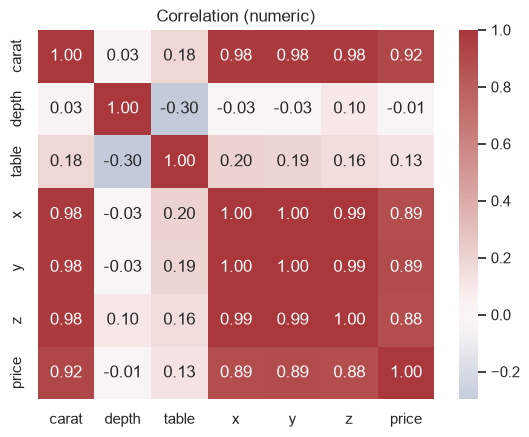

In [8]:
corr = df[NUM_COLS + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation (numeric)"); plt.show()

`carat`, `x`, `y`, `z` are almost perfectly correlated (all measure size). That's fine for prediction accuracy,
but it means per-feature importance gets split arbitrarily between them — don't read too much into which one ranks highest.

## 4. Train / test split & preprocessing pipeline

In [9]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)

def make_preprocessor(scale_numeric=False):
    num = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([
        ("grades", OrdinalEncoder(categories=[CATEGORY_ORDER[c] for c in CAT_COLS]), CAT_COLS),
        ("numeric", num, NUM_COLS),
    ])

def make_pipeline(model, scale_numeric=False):
    # Model learns log(1+price); predictions are converted back to dollars automatically.
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", make_preprocessor(scale_numeric)), ("model", model)]),
        func=np.log1p, inverse_func=np.expm1,
    )

candidates = {
    "Linear Regression": make_pipeline(LinearRegression(), scale_numeric=True),
    "Random Forest": make_pipeline(RandomForestRegressor(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)),
    "XGBoost": make_pipeline(XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=7, subsample=0.8,
                                         colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE)),
}

Train: (43017, 9) Test: (10755, 9)


## 5. Model comparison (5-fold cross-validation on the training set)

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in candidates.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=1,
                       scoring={"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"})
    rows.append({"model": name, "CV R2": s["test_r2"].mean(), "CV MAE ($)": -s["test_mae"].mean(),
                 "CV RMSE ($)": -s["test_rmse"].mean(), "fit time (s)": s["fit_time"].mean()})
    print(f"{name:18s} done")
cv_results = pd.DataFrame(rows).sort_values("CV MAE ($)").reset_index(drop=True)
cv_results.round(4)

Linear Regression  done


Random Forest      done


XGBoost            done


,model,CV R2,CV MAE ($),CV RMSE ($),fit time (s)
0,XGBoost,0.9823,259.7447,530.9905,2.1165
1,Random Forest,0.9808,271.0357,553.9331,1.9766
2,Linear Regression,0.9498,462.4988,895.5849,0.0594


In [11]:
best_name = cv_results.loc[0, "model"]
print("Best model by CV MAE:", best_name)

Best model by CV MAE: XGBoost


## 6. Fit best model & evaluate on held-out test set

In [12]:
best_model = candidates[best_name].fit(X_train, y_train)
pred = best_model.predict(X_test)

test_metrics = {
    "r2": r2_score(y_test, pred),
    "mae": mean_absolute_error(y_test, pred),
    "rmse": root_mean_squared_error(y_test, pred),
    "mape": mean_absolute_percentage_error(y_test, pred),
}
for k, v in test_metrics.items():
    print(f"{k.upper():5s}: {v:,.4f}")

R2   : 0.9830
MAE  : 258.5535
RMSE : 514.4576
MAPE : 0.0612


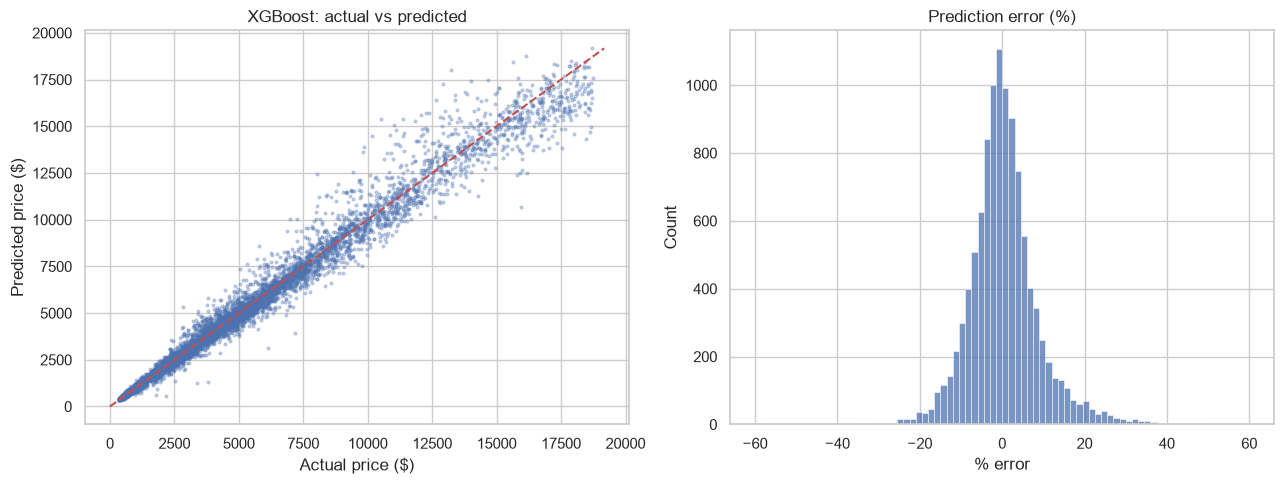

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, pred, s=4, alpha=.3)
lim = [0, max(y_test.max(), pred.max())]
axes[0].plot(lim, lim, "r--"); axes[0].set(xlabel="Actual price ($)", ylabel="Predicted price ($)", title=f"{best_name}: actual vs predicted")
residual_pct = (pred - y_test) / y_test * 100
sns.histplot(residual_pct.clip(-60, 60), bins=80, ax=axes[1]).set(title="Prediction error (%)", xlabel="% error")
plt.tight_layout(); plt.show()

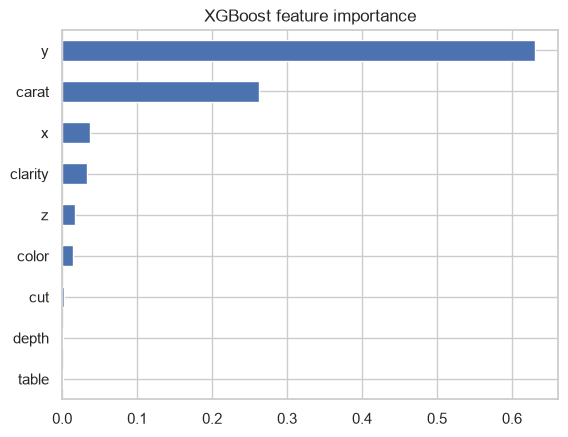

In [14]:
# Feature importance (tree models only)
reg = best_model.regressor_.named_steps["model"]
if hasattr(reg, "feature_importances_"):
    names = CAT_COLS + NUM_COLS
    imp = pd.Series(reg.feature_importances_, index=names).sort_values()
    imp.plot.barh(title=f"{best_name} feature importance"); plt.show()

## 7. Save the model for the web app

The saved file contains the **entire pipeline** (grade encoding → model → log back-transform),
so the app only needs to pass a one-row DataFrame with the 9 raw columns.

A metadata file stores input ranges (for the app's form limits) and a carat-vs-dimensions sanity ratio
so the app can warn when x/y/z don't match the carat entered.

In [15]:
# Refit on all cleaned data for the final model
final_model = clone(candidates[best_name]).fit(X, y)

joblib.dump(final_model, MODEL_DIR / "diamond_model.joblib", compress=3)

density = df["carat"] / (df["x"] * df["y"] * df["z"])  # carat per mm^3
metadata = {
    "model_name": best_name,
    "features": FEATURES,
    "category_order": CATEGORY_ORDER,
    "numeric_ranges": {c: {"min": float(df[c].min()), "max": float(df[c].max()),
                           "median": float(df[c].median())} for c in NUM_COLS},
    "carat_per_mm3": {"p01": float(density.quantile(0.01)), "p99": float(density.quantile(0.99))},
    "price_range": {"min": int(df[TARGET].min()), "max": int(df[TARGET].max())},
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "cv_results": cv_results.round(4).to_dict(orient="records"),
    "n_training_rows": int(len(df)),
    "versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__},
}
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved:", *sorted(p.name for p in MODEL_DIR.iterdir()))

Saved: diamond_model.joblib model_metadata.json


In [16]:
# Smoke test: reload and predict one diamond
loaded = joblib.load(MODEL_DIR / "diamond_model.joblib")
sample = pd.DataFrame([{"carat": 1.0, "cut": "Ideal", "color": "G", "clarity": "VS1",
                        "depth": 61.8, "table": 57.0, "x": 6.4, "y": 6.4, "z": 3.95}])
print(f"Predicted price: ${loaded.predict(sample)[0]:,.0f}")

Predicted price: $6,873
